# LLM-as-judge label audit — RelAmazon

This notebook inspects the consensus labels produced by the current signal-relevance-v7 judge protocol. Each model is run with three wording-only prompt variants; the root JSONL file stores the median/majority consensus label and the `variants/` subdirectory retains the three raw judgments for prompt-sensitivity analysis.

Agreement is not accuracy: without human relevance judgments, these comparisons show consistency/strictness, not which model is correct. A failed or incomplete consensus is kept distinct from grade 0.

In [49]:
from pathlib import Path
import sys

PROJECT_ROOT = Path("/storage/lcostes/Similarity_benchmark")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path("/storage/lcostes/Similarity_benchmark/annotations/rel-amazon/llm/signal-relevance-v7")

MODEL_ORDER = [
    "gemma-4-31b",
    "gpt-6-luna",
    "gpt-oss-120b",
    "mistral-small-3.2",
    "muse-glimmer-30b",
]

files = sorted(DATA_DIR.glob("*.jsonl"))
if not files:
    raise FileNotFoundError(f"No JSONL label files found in {DATA_DIR}")

frames = []
for path in files:
    frame = pd.read_json(path, lines=True)
    frame["model"] = path.stem
    frames.append(frame)

labels = pd.concat(frames, ignore_index=True, sort=False)
labels["grade"] = pd.to_numeric(labels.get("grade"), errors="coerce")
labels["status"] = labels.get("status", pd.Series("unknown", index=labels.index)).fillna("unknown").astype(str)
labels["condition_id"] = labels.get("condition_id", pd.Series("", index=labels.index)).fillna("").astype(str)
labels["candidate_id"] = labels.get("candidate_id", pd.Series("", index=labels.index)).fillna("").astype(str)
labels["pair_id"] = labels["condition_id"] + "::" + labels["candidate_id"]

models_found = [m for m in MODEL_ORDER if m in set(labels["model"])]
models_found += sorted(set(labels["model"]) - set(models_found))
print(f"Loaded {len(labels):,} rows from {len(files)} model file(s)")
print("Models:", ", ".join(models_found))
print("Prompt versions:", sorted(labels.get("prompt_version", pd.Series(dtype=str)).dropna().astype(str).unique()))
print("Data directory:", DATA_DIR)

Loaded 975 rows from 5 model file(s)
Models: gemma-4-31b, gpt-6-luna, gpt-oss-120b, mistral-small-3.2, muse-glimmer-30b
Prompt versions: ['signal-relevance-v7']
Data directory: /storage/lcostes/Similarity_benchmark/annotations/rel-amazon/llm/signal-relevance-v7


## 1. Coverage and response validity

Only rows with `status == "judged"` and an integer grade from 0 to 3 enter grade-distribution and agreement analyses. Unjudgeable, malformed, or failed outputs are coverage issues—not negative relevance labels.

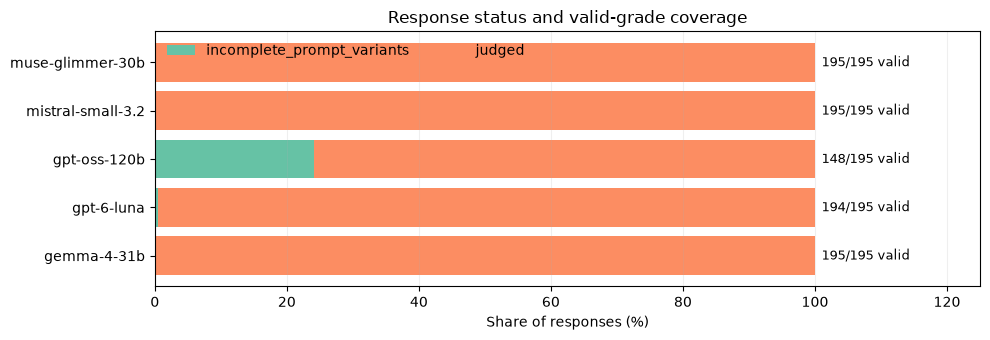

In [50]:
status_counts = (
    labels.groupby(["model", "status"], dropna=False)
    .size()
    .unstack(fill_value=0)
    .reindex(models_found)
)
status_counts["total"] = status_counts.sum(axis=1)
judged_valid = labels["status"].eq("judged") & labels["grade"].isin([0, 1, 2, 3])
valid_counts = labels[judged_valid].groupby("model").size().reindex(models_found, fill_value=0)
status_counts["valid graded"] = valid_counts
status_counts["valid graded %"] = (100 * status_counts["valid graded"] / status_counts["total"]).round(1)
status_columns = [c for c in status_counts.columns if c not in {"total", "valid graded", "valid graded %"}]
status_pct = status_counts[status_columns].div(status_counts["total"].replace(0, np.nan), axis=0) * 100
fig, ax = plt.subplots(figsize=(10, max(3.5, 0.55 * len(models_found))))
left = np.zeros(len(status_pct))
status_colors = plt.get_cmap("Set2").colors
for i, status in enumerate(status_columns):
    values = status_pct[status].fillna(0).to_numpy()
    ax.barh(status_pct.index, values, left=left, label=status, color=status_colors[i % len(status_colors)])
    left += values
for y, model in enumerate(status_pct.index):
    ax.text(101, y, f"{int(status_counts.loc[model, 'valid graded'])}/{int(status_counts.loc[model, 'total'])} valid", va="center", fontsize=9)
ax.set_xlim(0, 125)
ax.set_xlabel("Share of responses (%)")
ax.set_title("Response status and valid-grade coverage")
ax.legend(frameon=False, ncol=max(1, len(status_columns)))
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## 2. Grade distribution by model

Grades are treated as ordinal relevance judgments (0–3). The normalized chart makes model strictness easier to compare even if row coverage differs.

Grades meaning:
- 0 -> Irrelevant 
- 1 -> Weak or indirect relevance
- 2 -> Useful, but not central
- 3 -> Directly relevant or central to the intent

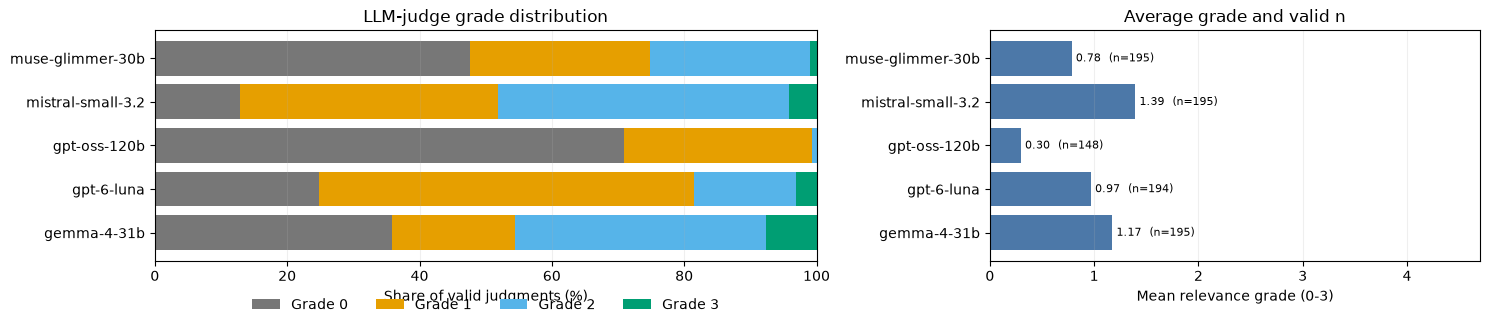

In [51]:
valid = labels[judged_valid].copy()
grade_counts = (
    valid.groupby(["model", "grade"]).size()
    .unstack(fill_value=0)
    .reindex(index=models_found, columns=[0, 1, 2, 3], fill_value=0)
)
grade_pct = grade_counts.div(grade_counts.sum(axis=1).replace(0, np.nan), axis=0) * 100

fig, (ax, ax_mean) = plt.subplots(1, 2, figsize=(15, max(3.5, 0.55 * len(models_found))), gridspec_kw={"width_ratios": [1.35, 1]})
left = np.zeros(len(grade_pct))
colors = ["#777777", "#e69f00", "#56b4e9", "#009e73"]
for grade, color in zip([0, 1, 2, 3], colors):
    vals = grade_pct[grade].fillna(0).to_numpy()
    ax.barh(grade_pct.index, vals, left=left, label=f"Grade {grade}", color=color)
    left += vals
ax.set_xlim(0, 100)
ax.set_xlabel("Share of valid judgments (%)")
ax.set_title("LLM-judge grade distribution")
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.28), frameon=False)
ax.grid(axis="x", alpha=0.2)
mean_grade = valid.groupby("model")["grade"].mean().reindex(models_found)
n_per_model = grade_counts.sum(axis=1).reindex(models_found)
ax_mean.barh(models_found, mean_grade, color="#4c78a8")
ax_mean.set_xlim(0, 4.7)
ax_mean.set_xlabel("Mean relevance grade (0-3)")
ax_mean.set_title("Average grade and valid n")
for y, model in enumerate(models_found):
    ax_mean.text(mean_grade.loc[model] + 0.04, y, f"{mean_grade.loc[model]:.2f}  (n={int(n_per_model.loc[model])})", va="center", fontsize=8)
ax_mean.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## 3. Pairwise agreement on shared pairs

For each model pair, the notebook uses only condition–signal pairs with valid grades from both models. Metrics:

- **Exact agreement:** fraction of pairs receiving the same 0–3 grade.
- **Quadratic weighted κ:** chance-corrected ordinal agreement. It is 1 for perfect agreement, about 0 when agreement is no better than expected by chance, and can be negative when it is worse. A one-grade difference is penalized less than a two- or three-grade difference.
- **Binary agreement (grade ≥2):** the share of pairs where both models make the same broad call: grades 0–1 versus grades 2–3. It ignores differences within each group (for example, 2 versus 3 counts as agreement).
- **Mean absolute grade difference:** average distance on the 0–3 scale.

Pair counts matter: agreement estimates are comparable only when their shared coverage is similar.

In [52]:
def quadratic_weighted_kappa(a, b, n_grades=4):
    a = np.asarray(a, dtype=int)
    b = np.asarray(b, dtype=int)
    if len(a) == 0:
        return np.nan
    observed = np.zeros((n_grades, n_grades), dtype=float)
    for x, y in zip(a, b):
        observed[x, y] += 1
    observed /= len(a)
    expected = np.outer(np.bincount(a, minlength=n_grades), np.bincount(b, minlength=n_grades)).astype(float)
    expected /= max(1, len(a) ** 2)
    levels = np.arange(n_grades)
    weights = ((levels[:, None] - levels[None, :]) / (n_grades - 1)) ** 2
    denom = np.sum(weights * expected)
    return np.nan if denom == 0 else 1 - np.sum(weights * observed) / denom

wide = valid.pivot_table(index="pair_id", columns="model", values="grade", aggfunc="first")
pairwise_rows = []
for i, model_a in enumerate(models_found):
    for model_b in models_found[i + 1:]:
        if model_a not in wide or model_b not in wide:
            continue
        both = wide[[model_a, model_b]].dropna()
        if both.empty:
            continue
        a = both[model_a].astype(int).to_numpy()
        b = both[model_b].astype(int).to_numpy()
        pairwise_rows.append({
            "model A": model_a,
            "model B": model_b,
            "shared pairs": len(both),
            "exact agreement": np.mean(a == b),
            "weighted kappa": quadratic_weighted_kappa(a, b),
            "binary agreement (grade ≥2)": np.mean((a >= 2) == (b >= 2)),
            "mean absolute grade difference": np.mean(np.abs(a - b)),
            "within-one-grade agreement": np.mean(np.abs(a - b) <= 1),
        })
pairwise = pd.DataFrame(pairwise_rows, columns=["model A", "model B", "shared pairs", "exact agreement", "weighted kappa", "binary agreement (grade ≥2)", "mean absolute grade difference", "within-one-grade agreement"])
if pairwise.empty:
    print("No model pairs have overlapping valid judgments yet.")
else:
    print(f"Pairwise model-pair metrics — sorted by weighted κ, then shared-pair count")
    display(pairwise.sort_values(["weighted kappa", "shared pairs"], ascending=[False, False]).round(3))

Pairwise model-pair metrics — sorted by weighted κ, then shared-pair count


,model A,model B,shared pairs,exact agreement,weighted kappa,binary agreement (grade ≥2),mean absolute grade difference,within-one-grade agreement
2,gemma-4-31b,mistral-small-3.2,195,0.605,0.722,0.872,0.415,0.979
3,gemma-4-31b,muse-glimmer-30b,195,0.574,0.667,0.774,0.492,0.933
6,gpt-6-luna,muse-glimmer-30b,194,0.582,0.647,0.845,0.428,0.990
0,gemma-4-31b,gpt-6-luna,194,0.469,0.625,0.732,0.552,0.979
9,mistral-small-3.2,muse-glimmer-30b,195,0.436,0.522,0.749,0.641,0.923
5,gpt-6-luna,mistral-small-3.2,194,0.433,0.509,0.665,0.588,0.979
8,gpt-oss-120b,muse-glimmer-30b,148,0.439,0.151,0.709,0.743,0.824
4,gpt-6-luna,gpt-oss-120b,148,0.331,0.129,0.777,0.824,0.865
7,gpt-oss-120b,mistral-small-3.2,148,0.176,0.066,0.473,1.203,0.655
1,gemma-4-31b,gpt-oss-120b,148,0.338,0.062,0.507,1.088,0.642


### Pairwise metric heatmaps and model-to-peer summary

The heatmaps show ordinal agreement, exact and binary agreement, within-one-grade agreement, average absolute grade difference, and the number of shared pairs. Within-one-grade agreement counts a pair as acceptable when the grades differ by at most one point. Blank cells indicate no shared valid judgments. The bars below aggregate each model’s comparisons against all peers: lower mean absolute grade difference and higher weighted κ indicate greater overall similarity to the other judges.

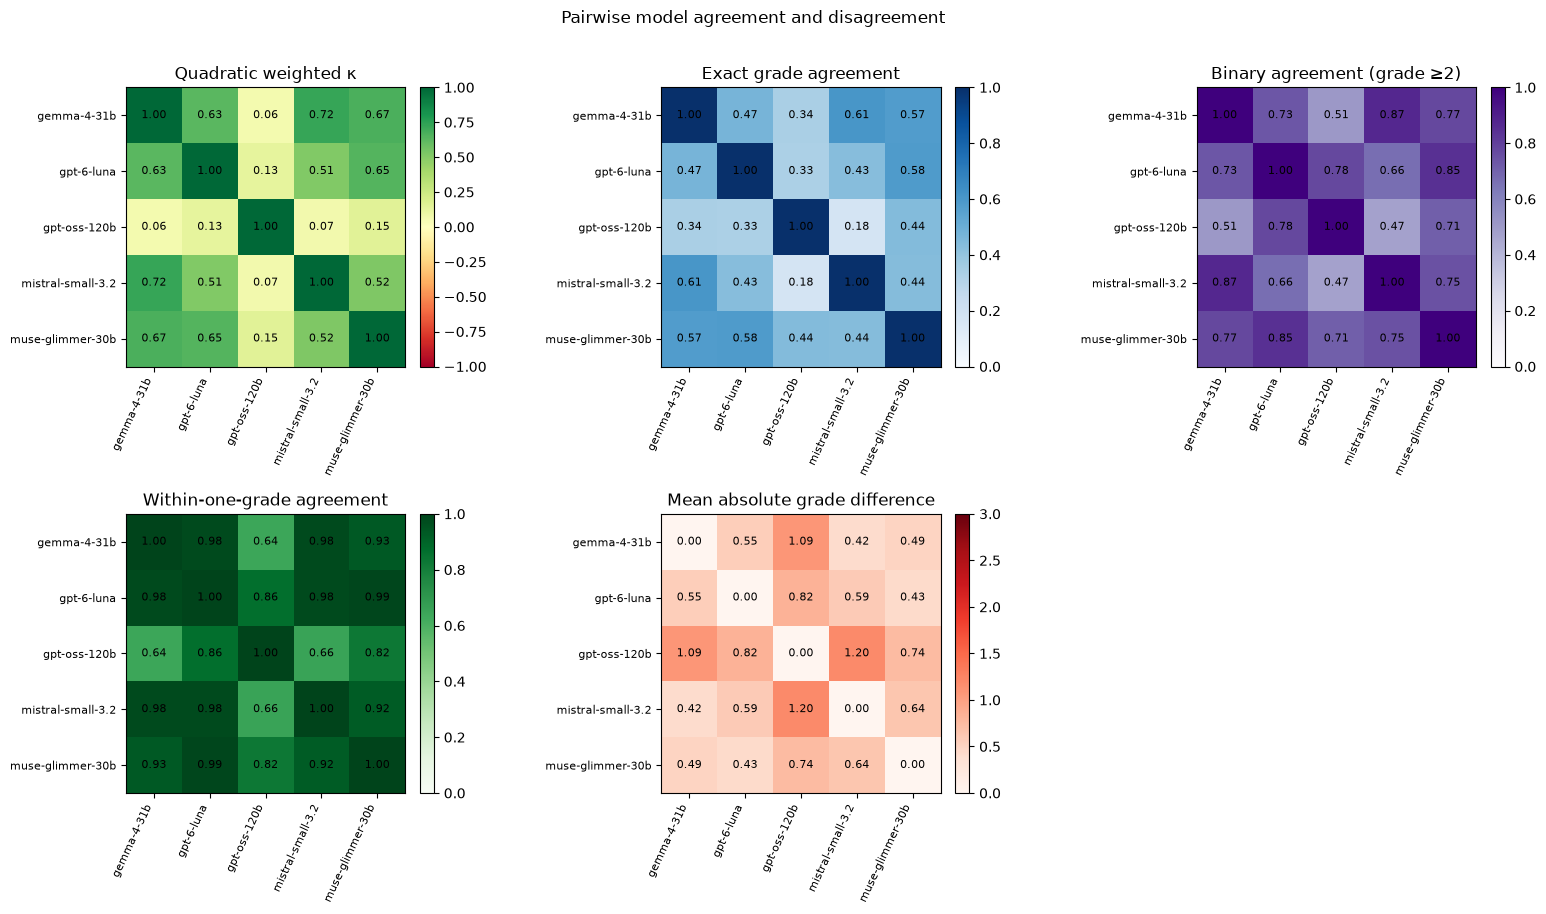

Model similarity to all peers — sorted by mean absolute grade difference (lower means closer)


,similarity rank,peer comparisons,mean absolute grade difference (lower = closer),mean weighted κ (higher = closer),mean binary agreement,mean within-one-grade agreement
model,,,,,,
muse-glimmer-30b,1,4,0.576,0.497,0.769,0.918
gpt-6-luna,2,4,0.598,0.478,0.755,0.953
gemma-4-31b,3,4,0.637,0.519,0.721,0.884
mistral-small-3.2,4,4,0.712,0.455,0.690,0.884
gpt-oss-120b,5,4,0.965,0.102,0.617,0.747


In [53]:
def symmetric_metric_matrix(metric):
    matrix = pd.DataFrame(np.nan, index=models_found, columns=models_found)
    if metric == "mean absolute grade difference":
        diagonal = 0.0
    else:
        diagonal = 1.0
    for model in models_found:
        matrix.loc[model, model] = diagonal
    if not pairwise.empty:
        for _, row in pairwise.iterrows():
            matrix.loc[row["model A"], row["model B"]] = row[metric]
            matrix.loc[row["model B"], row["model A"]] = row[metric]
    return matrix

metric_specs = [
    ("weighted kappa", "Quadratic weighted κ", -1, 1, "RdYlGn"),
    ("exact agreement", "Exact grade agreement", 0, 1, "Blues"),
    ("binary agreement (grade ≥2)", "Binary agreement (grade ≥2)", 0, 1, "Purples"),
    ("within-one-grade agreement", "Within-one-grade agreement", 0, 1, "Greens"),
    ("mean absolute grade difference", "Mean absolute grade difference", 0, 3, "Reds"),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (metric, title, vmin, vmax, cmap) in zip(axes.flat, metric_specs):
    matrix = symmetric_metric_matrix(metric)
    image = ax.imshow(matrix.to_numpy(dtype=float), vmin=vmin, vmax=vmax, cmap=cmap)
    ax.set_xticks(range(len(models_found)), models_found, rotation=65, ha="right", fontsize=8)
    ax.set_yticks(range(len(models_found)), models_found, fontsize=8)
    ax.set_title(title)
    for r in range(len(models_found)):
        for c in range(len(models_found)):
            value = matrix.iloc[r, c]
            if pd.notna(value):
                ax.text(c, r, f"{value:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
axes.flat[-1].set_visible(False)
plt.suptitle("Pairwise model agreement and disagreement", y=1.01)
plt.tight_layout()
plt.show()

# Aggregate each judge's pairwise differences from all its peers.
peer_rows = []
for model in models_found:
    peers = pairwise[(pairwise["model A"] == model) | (pairwise["model B"] == model)]
    peer_rows.append({
        "model": model,
        "peer comparisons": len(peers),
        "average absolute grade difference to peers": peers["mean absolute grade difference"].mean(),
        "average weighted κ with peers": peers["weighted kappa"].mean(),
        "average binary agreement with peers": peers["binary agreement (grade ≥2)"].mean(),
        "average within-one-grade agreement with peers": peers["within-one-grade agreement"].mean(),
    })
peer_summary = pd.DataFrame(peer_rows).set_index("model").reindex(models_found)
peer_summary_display = peer_summary.sort_values("average absolute grade difference to peers", ascending=True).copy()
print("Model similarity to all peers — sorted by mean absolute grade difference (lower means closer)")
peer_summary_display.insert(0, "similarity rank", np.arange(1, len(peer_summary_display) + 1))
display(peer_summary_display.rename(columns={
    "average absolute grade difference to peers": "mean absolute grade difference (lower = closer)",
    "average weighted κ with peers": "mean weighted κ (higher = closer)",
    "average binary agreement with peers": "mean binary agreement",
    "average within-one-grade agreement with peers": "mean within-one-grade agreement",
}).round(3))

In [54]:
from pathlib import Path
import sys

PROJECT_ROOT = Path("/storage/lcostes/Similarity_benchmark")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from IPython.display import clear_output, display, Markdown
from src.datasets.local_relbench_dataset import LocalRelBenchDataset
from src.schema.schema_graph import SchemaGraph
from src.signals.candidates import candidate_from_dict

JUDGE_DATASET_ROOT = Path("/storage/lcostes/Similarity_benchmark/data/dev/rel-amazon")
JUDGE_GRAPH = SchemaGraph.from_manifest(LocalRelBenchDataset(JUDGE_DATASET_ROOT).schema)

def human_signal_details(candidate):
    if not isinstance(candidate, dict):
        return "(Stored signal metadata is unavailable.)", ""
    explanation = candidate.get("human_explanation")
    diagram = candidate.get("path_diagram")
    if isinstance(explanation, str) and isinstance(diagram, str):
        return explanation, diagram
    restored = candidate_from_dict(candidate)
    return restored.explain_for_human(JUDGE_GRAPH), restored.human_diagram(JUDGE_GRAPH)

# Show only maximum-gap pairs: at least one judge gave 0 and another gave 3.
disagreement_rows = []
for pair_id, grades in wide.iterrows():
    grades = grades.dropna().astype(int)
    if len(grades) < 2:
        continue
    low, high = int(grades.min()), int(grades.max())
    if high - low != 3:
        continue
    pair_labels = valid[valid["pair_id"].eq(pair_id)]
    item = pair_labels.iloc[0]
    candidate = item.get("candidate")
    description = candidate.get("description", str(candidate)) if isinstance(candidate, dict) else str(candidate)
    explanation, diagram = human_signal_details(candidate)
    disagreement_rows.append({
        "pair_id": pair_id,
        "condition_id": item.get("condition_id"),
        "condition": item.get("condition"),
        "candidate_id": item.get("candidate_id"),
        "signal": description,
        "what it means": explanation,
        "path diagram": diagram,
        "grade gap": high - low,
        "extreme 0 vs 3": low == 0 and high == 3,
        "grades by model": grades.to_dict(),
    })

disagreements = pd.DataFrame(disagreement_rows)
if disagreements.empty:
    print("No shared pairs have the maximum 3-point grade gap (0 versus 3).")
else:
    disagreements = disagreements.sort_values(["extreme 0 vs 3", "grade gap"], ascending=False).reset_index(drop=True)
    print(f"{len(disagreements)} pair(s) have the maximum 3-point gap (one or more models graded 0 and another graded 3).")
    try:
        import ipywidgets as widgets
    except ImportError:
        widgets = None

    def show_disagreement(index):
        pair = disagreements.iloc[int(index)]
        pair_labels = valid[valid["pair_id"].eq(pair["pair_id"])].sort_values(["grade", "model"], ascending=[True, True])
        display(Markdown(f"## {pair['condition_id']} — {pair['candidate_id']}\n\n**Intent:** {pair['condition']}\n\n**Signal:** {pair['signal']}\n\n**What it means:** {pair['what it means']}\n\n```text\n{pair['path diagram']}\n```\n\n**Grade spread:** {pair['grade gap']} point(s)\n\n**Grades by model:** {pair['grades by model']}"))
        for _, judgment in pair_labels.iterrows():
            display(Markdown(f"### {judgment['model']} — consensus Grade {int(judgment['grade'])}"))
            variant_judgments = judgment.get("variant_judgments")
            if isinstance(variant_judgments, dict):
                for variant in ("standard", "paraphrase-a", "paraphrase-b"):
                    variant_judgment = variant_judgments.get(variant)
                    if not isinstance(variant_judgment, dict):
                        continue
                    reason = variant_judgment.get("reason") or "(No rationale saved.)"
                    variant_grade = variant_judgment.get("grade")
                    grade_label = f"Grade {variant_grade}" if variant_grade is not None else "unjudged"
                    display(Markdown(f"#### {variant} — {grade_label}\n\n{reason}"))
            else:
                reason = judgment.get("reason")
                if pd.isna(reason) or not str(reason).strip():
                    reason = "(No rationale saved.)"
                display(Markdown(f"#### Rationale\n\n{reason}"))

    if widgets is None:
        print("ipywidgets is unavailable; call show_disagreement(0), show_disagreement(1), etc. to browse.")
        show_disagreement(0)
    else:
        selector = widgets.Dropdown(
            options=[(f"{i + 1}. {'0-vs-3' if row['extreme 0 vs 3'] else 'gap ' + str(row['grade gap'])} | {row['condition_id']} | {row['candidate_id']}", i) for i, row in disagreements.iterrows()],
            description="Pair:",
            layout=widgets.Layout(width="95%"),
        )
        detail_output = widgets.Output()

        def _render_selected(change=None):
            with detail_output:
                clear_output(wait=True)
                show_disagreement(selector.value)

        selector.observe(_render_selected, names="value")
        display(selector, detail_output)
        _render_selected()

11 pair(s) have the maximum 3-point gap (one or more models graded 0 and another graded 3).


Dropdown(description='Pair:', layout=Layout(width='95%'), options=(('1. 0-vs-3 | condition-001 | attribute:pro…

Output()

## Prompt wording sensitivity

This section measures how much each model’s grade changes across wording-only prompt variants for the same condition–signal pair. The intent, schema, candidate, rubric, section order, decoding settings, and seed are held constant. The first plot shows the distribution of each pair’s grade range across variants (maximum minus minimum); range 0 means perfectly stable, range 1 means at most a one-grade change, and range 2–3 means stronger prompt sensitivity. The second plot reports mean per-pair grade variance across variants. These measure prompt stability, not correctness. This is not a position-bias experiment: each judgment contains one signal, so no candidate ordering is manipulated.

Loaded 2,859 valid judgments across 5 model configurations and 3 wording variants.


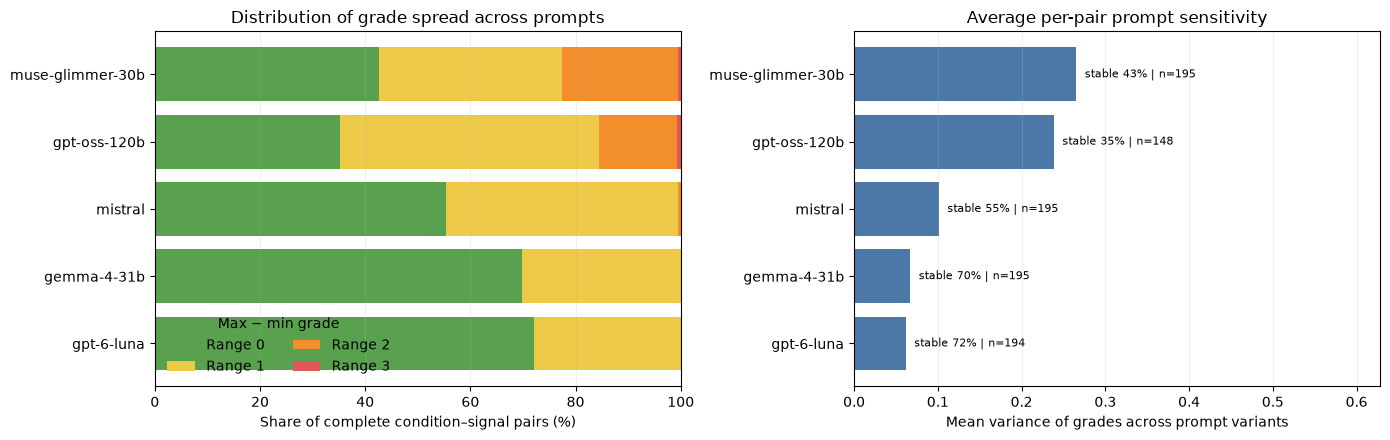

In [55]:
PROMPT_VARIANT_DIR = DATA_DIR / "variants"
variant_files = sorted(PROMPT_VARIANT_DIR.glob("*.jsonl"))
if not variant_files:
    print(f"No prompt-variant results found yet in {PROMPT_VARIANT_DIR}")
else:
    variant_frames = []
    for path in variant_files:
        frame = pd.read_json(path, lines=True)
        frame["variant"] = frame["prompt_variant"] if "prompt_variant" in frame else path.stem.rsplit("__", 1)[-1]
        frame["model"] = frame["judge_model_family"] if "judge_model_family" in frame else path.stem.split("__")[0]
        if "reasoning_effort" not in frame:
            frame["reasoning_effort"] = "none"
        frame["pair_id"] = frame["condition_id"].astype(str) + "::" + frame["candidate_id"].astype(str)
        frame["grade"] = pd.to_numeric(frame["grade"], errors="coerce")
        variant_frames.append(frame)
    variant_labels = pd.concat(variant_frames, ignore_index=True, sort=False)
    variant_labels = variant_labels[variant_labels["status"].eq("judged") & variant_labels["grade"].isin([0, 1, 2, 3])].copy()
    print(f"Loaded {len(variant_labels):,} valid judgments across {variant_labels['model'].nunique()} model configurations and {variant_labels['variant'].nunique()} wording variants.")

    stability_rows = []
    range_rows = []
    for model, model_data in variant_labels.groupby("model"):
        grades_by_variant = model_data.pivot_table(index="pair_id", columns="variant", values="grade", aggfunc="first")
        variant_names = list(grades_by_variant.columns)
        if len(variant_names) < 2:
            continue
        complete = grades_by_variant.dropna(subset=variant_names)
        if complete.empty:
            continue
        grade_range = complete.max(axis=1) - complete.min(axis=1)
        pair_variance = complete.var(axis=1, ddof=0)
        stability_rows.append({
            "model": model,
            "complete pairs": len(complete),
            "perfectly stable %": 100 * np.mean(grade_range == 0),
            "within-one-grade %": 100 * np.mean(grade_range <= 1),
            "mean grade range": grade_range.mean(),
            "mean per-pair grade variance": pair_variance.mean(),
        })
        for spread in range(4):
            range_rows.append({"model": model, "grade range": spread, "share %": 100 * np.mean(grade_range == spread)})

    stability = pd.DataFrame(stability_rows)
    if stability.empty:
        print("No model has complete judgments for the same pairs under two or more variants yet.")
    else:
        model_order = stability.sort_values("mean per-pair grade variance")["model"].tolist()
        range_distribution = (
            pd.DataFrame(range_rows)
            .pivot(index="model", columns="grade range", values="share %")
            .reindex(index=model_order, columns=range(4), fill_value=0)
            .fillna(0)
        )
        fig, axes = plt.subplots(1, 2, figsize=(14, max(4.5, 0.55 * len(model_order))))
        left = np.zeros(len(model_order))
        range_colors = ["#59a14f", "#edc948", "#f28e2b", "#e15759"]
        for spread in range(4):
            values = range_distribution[spread].to_numpy()
            axes[0].barh(model_order, values, left=left, color=range_colors[spread], label=f"Range {spread}")
            left += values
        axes[0].set_xlim(0, 100)
        axes[0].set_xlabel("Share of complete condition–signal pairs (%)")
        axes[0].set_title("Distribution of grade spread across prompts")
        axes[0].legend(title="Max − min grade", frameon=False, ncol=2)
        axes[0].grid(axis="x", alpha=0.2)

        variance_by_model = stability.set_index("model").reindex(model_order)
        bars = axes[1].barh(model_order, variance_by_model["mean per-pair grade variance"], color="#4c78a8")
        max_variance = variance_by_model["mean per-pair grade variance"].max()
        axes[1].set_xlim(0, max(0.1, max_variance * 1.8 + 0.15))
        axes[1].set_xlabel("Mean variance of grades across prompt variants")
        axes[1].set_title("Average per-pair prompt sensitivity")
        axes[1].grid(axis="x", alpha=0.2)
        for bar, (_, row) in zip(bars, variance_by_model.iterrows()):
            axes[1].text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2, f"stable {row['perfectly stable %']:.0f}% | n={int(row['complete pairs'])}", va="center", fontsize=8)
        plt.tight_layout()
        plt.show()

## Human labels compared with each judge

This section compares the 195 labels from `annotations/rel-amazon/human/lysandre.jsonl` with each model’s consensus grade for the same condition–signal pair. It reports exact agreement, quadratic weighted kappa (which gives smaller penalties to one-grade disagreements), agreement on the binary split grade ≥2, within-one-grade agreement (the share of pairs where model and human grades differ by no more than one point), mean absolute grade difference, and mean grade difference (model minus human). The mean absolute grade difference measures disagreement size without direction; the mean grade difference shows whether the model tends to grade higher (positive) or lower (negative) than the human annotator.

These are agreement measures against one annotator, not model accuracy or an objective ground truth. GPT‑OSS has some unfinished consensus rows; those are excluded from its pairwise metrics and shown as missing in the coverage summary.

In [56]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path("/storage/lcostes/Similarity_benchmark")
HUMAN_LABEL_PATH = PROJECT_ROOT / "annotations/rel-amazon/human/lysandre.jsonl"
HUMAN_MODEL_FILES = {
    "Muse Glimmer": PROJECT_ROOT / "annotations/rel-amazon/llm/signal-relevance-v7/muse-glimmer-30b.jsonl",
    "Gemma 4": PROJECT_ROOT / "annotations/rel-amazon/llm/signal-relevance-v7/gemma-4-31b.jsonl",
    "Mistral Small 3.2": PROJECT_ROOT / "annotations/rel-amazon/llm/signal-relevance-v7/mistral-small-3.2.jsonl",
    "GPT-OSS 120B": PROJECT_ROOT / "annotations/rel-amazon/llm/signal-relevance-v7/gpt-oss-120b.jsonl",
    "GPT-6 Luna (OCI)": PROJECT_ROOT / "annotations/rel-amazon/llm/signal-relevance-v7/gpt-6-luna.jsonl",
}
GRADE_VALUES = [0, 1, 2, 3]

human_raw = pd.read_json(HUMAN_LABEL_PATH, lines=True)
human_raw["grade"] = pd.to_numeric(human_raw["grade"], errors="coerce")
human = human_raw[
    human_raw["status"].eq("complete") & human_raw["grade"].isin(GRADE_VALUES)
].copy()
if human.duplicated(["condition_id", "candidate_id"]).any():
    raise ValueError("Human annotation file has duplicate condition/candidate pairs")
human = human.rename(columns={"grade": "human_grade", "rationale": "human_rationale"})

pair_frames = []
coverage_rows = []
for model_name, model_path in HUMAN_MODEL_FILES.items():
    if not model_path.is_file():
        coverage_rows.append({"model": model_name, "rows": 0, "valid consensus": 0, "missing/invalid": len(human)})
        continue
    model_raw = pd.read_json(model_path, lines=True)
    model_raw["grade"] = pd.to_numeric(model_raw.get("grade"), errors="coerce")
    model_valid = model_raw[
        model_raw["status"].eq("judged") & model_raw["grade"].isin(GRADE_VALUES)
    ].copy()
    if model_raw.duplicated(["condition_id", "candidate_id"]).any():
        raise ValueError(f"{model_name} file has duplicate condition/candidate pairs")
    coverage_rows.append({
        "model": model_name,
        "rows": len(model_raw),
        "valid consensus": len(model_valid),
        "missing/invalid": len(model_raw) - len(model_valid),
    })
    keep_human = human[[
        "condition_id", "candidate_id", "condition", "human_grade",
        "human_rationale", "candidate",
    ]]
    keep_model = model_valid[[
        "condition_id", "candidate_id", "grade", "reason", "status", "variant_judgments",
    ]].rename(columns={"grade": "model_grade", "reason": "model_reason", "status": "model_status"})
    paired = keep_human.merge(keep_model, on=["condition_id", "candidate_id"], how="inner")
    paired["model"] = model_name
    paired["grade_gap"] = paired["model_grade"] - paired["human_grade"]
    paired["absolute_gap"] = paired["grade_gap"].abs()
    pair_frames.append(paired)

human_model_long = pd.concat(pair_frames, ignore_index=True) if pair_frames else pd.DataFrame()
if human_model_long.empty:
    raise ValueError("No valid model labels overlap the human annotation pairs")

coverage = pd.DataFrame(coverage_rows).set_index("model").reindex(HUMAN_MODEL_FILES).reset_index()
coverage["coverage %"] = 100 * coverage["valid consensus"] / max(1, len(human))
print(f"Human labels: {len(human):,} valid pairs across {human['condition_id'].nunique()} conditions")
display(coverage.round({"coverage %": 1}))

def human_weighted_kappa(human_grades, model_grades):
    a = np.asarray(human_grades, dtype=int)
    b = np.asarray(model_grades, dtype=int)
    if len(a) == 0:
        return np.nan
    observed = np.zeros((4, 4), dtype=float)
    np.add.at(observed, (a, b), 1)
    expected = np.outer(np.bincount(a, minlength=4), np.bincount(b, minlength=4)) / len(a)
    weights = np.fromfunction(lambda i, j: ((i - j) / 3.0) ** 2, (4, 4))
    denominator = float((weights * expected).sum())
    return 1.0 - float((weights * observed).sum()) / denominator if denominator else np.nan

metric_rows = []
for model_name, group in human_model_long.groupby("model", sort=False):
    a = group["human_grade"].to_numpy(dtype=int)
    b = group["model_grade"].to_numpy(dtype=int)
    metric_rows.append({
        "model": model_name,
        "shared pairs": len(group),
        "exact agreement": np.mean(a == b),
        "weighted kappa": human_weighted_kappa(a, b),
        "binary agreement (≥2)": np.mean((a >= 2) == (b >= 2)),
        "within-one-grade agreement": np.mean(np.abs(b - a) <= 1),
        "mean absolute grade difference": np.mean(np.abs(b - a)),
        "mean grade difference": np.mean(b - a),
    })
model_human_metrics = pd.DataFrame(metric_rows).set_index("model").reindex(HUMAN_MODEL_FILES).reset_index()
display(model_human_metrics.sort_values(["weighted kappa", "exact agreement"], ascending=False, na_position="last").round(3))


Human labels: 195 valid pairs across 5 conditions


,model,rows,valid consensus,missing/invalid,coverage %
0,Muse Glimmer,195,195,0,100.0
1,Gemma 4,195,195,0,100.0
2,Mistral Small 3.2,195,195,0,100.0
3,GPT-OSS 120B,195,148,47,75.9
4,GPT-6 Luna (OCI),195,194,1,99.5


,model,shared pairs,exact agreement,weighted kappa,binary agreement (≥2),within-one-grade agreement,mean absolute grade difference,mean grade difference
4,GPT-6 Luna (OCI),194,0.562,0.688,0.881,1.000,0.438,0.149
0,Muse Glimmer,195,0.585,0.667,0.877,0.964,0.451,-0.031
1,Gemma 4,195,0.523,0.616,0.733,0.903,0.574,0.359
2,Mistral Small 3.2,195,0.395,0.476,0.697,0.892,0.713,0.579
3,GPT-OSS 120B,148,0.473,0.101,0.777,0.831,0.757,-0.608


### Agreement patterns

The first plot compares the main agreement measures. The condition heatmaps reveal whether agreement changes with the intent and whether a model tends to grade more leniently or harshly than you. Confusion matrices show which grade pairs account for the gaps; rows are your grades and columns are model grades.

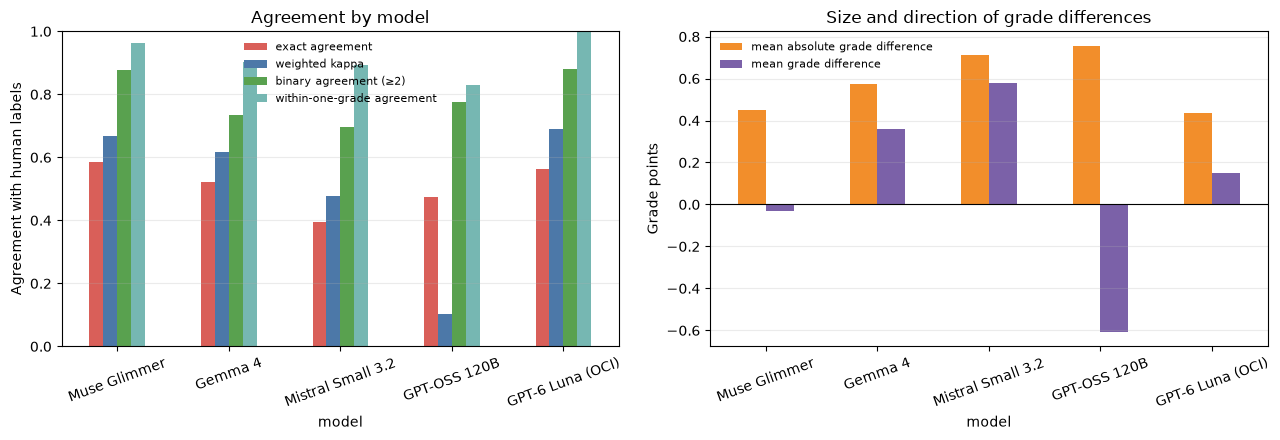

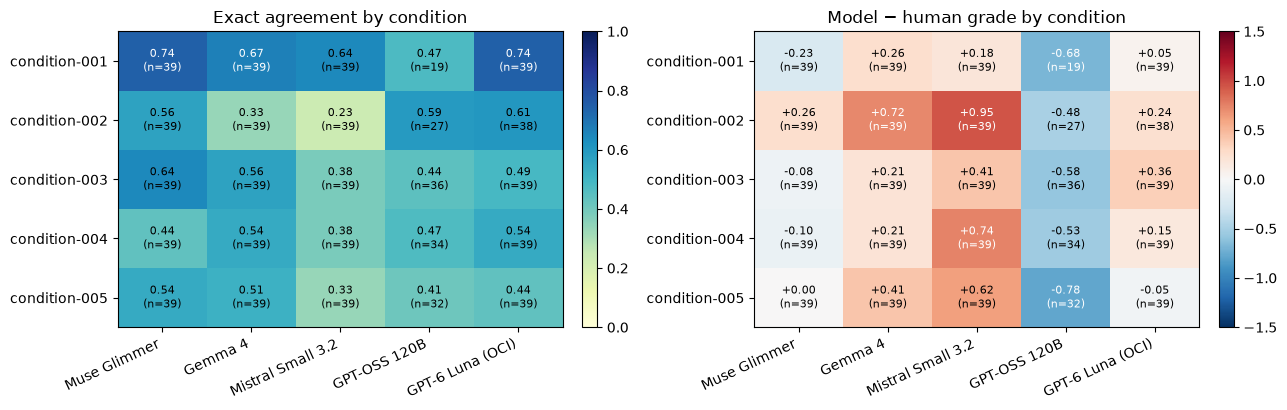

In [57]:
plot_metrics = model_human_metrics.dropna(subset=["model"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_metrics.set_index("model")[["exact agreement", "weighted kappa", "binary agreement (≥2)", "within-one-grade agreement"]].plot(
    kind="bar", ax=axes[0], color=["#d95f59", "#4c78a8", "#59a14f", "#76b7b2"]
)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Agreement with human labels")
axes[0].set_title("Agreement by model")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(frameon=False, fontsize=8)
plot_metrics.set_index("model")[["mean absolute grade difference", "mean grade difference"]].plot(
    kind="bar", ax=axes[1], color=["#f28e2b", "#7b61a8"]
)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("Grade points")
axes[1].set_title("Size and direction of grade differences")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

condition_order = sorted(human_model_long["condition_id"].unique())
model_order = list(HUMAN_MODEL_FILES)
condition_rows = []
for (condition_id, model_name), group in human_model_long.groupby(["condition_id", "model"], sort=False):
    a = group["human_grade"].to_numpy(dtype=int)
    b = group["model_grade"].to_numpy(dtype=int)
    condition_rows.append({
        "condition_id": condition_id,
        "model": model_name,
        "n": len(group),
        "exact agreement": np.mean(a == b),
        "mean grade difference": np.mean(b - a),
    })
condition_metrics = pd.DataFrame(condition_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, metric, title, cmap, limits in [
    (axes[0], "exact agreement", "Exact agreement by condition", "YlGnBu", (0, 1)),
    (axes[1], "mean grade difference", "Model − human grade by condition", "RdBu_r", (-1.5, 1.5)),
]:
    matrix = condition_metrics.pivot(index="condition_id", columns="model", values=metric).reindex(index=condition_order, columns=model_order)
    image = ax.imshow(matrix.to_numpy(dtype=float), cmap=cmap, vmin=limits[0], vmax=limits[1], aspect="auto")
    ax.set_xticks(range(len(model_order)), model_order, rotation=25, ha="right")
    ax.set_yticks(range(len(condition_order)), condition_order)
    ax.set_title(title)
    for row_index, condition_id in enumerate(condition_order):
        for col_index, model_name in enumerate(model_order):
            value = matrix.loc[condition_id, model_name]
            count = condition_metrics.loc[
                condition_metrics["condition_id"].eq(condition_id) & condition_metrics["model"].eq(model_name), "n"
            ]
            if pd.notna(value):
                label = f"{value:.2f}" if metric == "exact agreement" else f"{value:+.2f}"
                if len(count):
                    label += f"\n(n={int(count.iloc[0])})"
                ax.text(col_index, row_index, label, ha="center", va="center", fontsize=8,
                        color="white" if abs(value) > 0.65 else "black")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


### Browse individual disagreements

Select a model and condition to inspect the largest grade gaps first. Each entry shows your label, the model consensus label, the signal path, and the saved explanations.

In [58]:
import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

browser_model = widgets.Dropdown(options=model_order, value=model_order[0], description="Model:")
browser_condition = widgets.Dropdown(options=["All conditions"] + condition_order, description="Condition:")
browser_pair = widgets.Dropdown(description="Pair:", layout=widgets.Layout(width="95%"))
browser_output = widgets.Output()
last_human_pair_render = None

def refresh_human_pair_options(*_):
    subset = human_model_long[human_model_long["model"].eq(browser_model.value)].copy()
    if browser_condition.value != "All conditions":
        subset = subset[subset["condition_id"].eq(browser_condition.value)]
    subset = subset.sort_values(["absolute_gap", "candidate_id"], ascending=[False, True])
    options = []
    for index, row in subset.iterrows():
        label = (f"{row['condition_id']} | human {int(row['human_grade'])} → model "
                 f"{int(row['model_grade'])} | gap {int(row['absolute_gap'])} | {row['candidate_id']}")
        options.append((label, int(index)))
    browser_pair.options = options
    if options:
        browser_pair.value = options[0][1]
    else:
        browser_pair.value = None


def show_human_pair(change=None):
    global last_human_pair_render
    render_key = (browser_model.value, browser_condition.value, browser_pair.value)
    if render_key == last_human_pair_render:
        return
    last_human_pair_render = render_key
    with browser_output:
        clear_output(wait=False)
        if browser_pair.value is None:
            print("No overlapping valid labels for this selection.")
            return
        row = human_model_long.loc[browser_pair.value]
        candidate = row.get("candidate")
        if not isinstance(candidate, dict):
            candidate = {}
        signal_text = candidate.get("human_explanation") or candidate.get("description") or row["candidate_id"]
        path_text = candidate.get("path_diagram") or candidate.get("description") or row["candidate_id"]
        display(Markdown(
            f"**{row['condition_id']} — {row['candidate_id']}**\n\n"
            f"**Intent:** {row['condition']}\n\n"
            f"**Signal:** {signal_text}\n\n"
            f"**Path:**\n```text\n{path_text}\n```\n\n"
            f"**Human grade:** {int(row['human_grade'])}  |  **{row['model']} grade:** {int(row['model_grade'])}  |  "
            f"**Model − human:** {int(row['grade_gap']):+d}"
        ))
        human_rationale = row.get("human_rationale")
        if isinstance(human_rationale, str) and human_rationale.strip():
            display(Markdown("**Human rationale:**\n\n" + human_rationale))
        else:
            display(Markdown("**Human rationale:** none was saved for this annotation."))
        model_reason = row.get("model_reason")
        if (isinstance(model_reason, str) and model_reason.strip()
                and not (isinstance(row.get("variant_judgments"), dict) and row.get("variant_judgments"))):
            display(Markdown("**Model reason:**\n\n" + model_reason))
        variant_judgments = row.get("variant_judgments")
        if isinstance(variant_judgments, dict) and variant_judgments:
            variant_table = pd.DataFrame([
                {"prompt variant": name, "grade": value.get("grade")}
                for name, value in variant_judgments.items() if isinstance(value, dict)
            ])
            if not variant_table.empty:
                display(variant_table, index=False)
                for name, value in variant_judgments.items():
                    if not isinstance(value, dict):
                        continue
                    reason = value.get("reason")
                    if isinstance(reason, str) and reason.strip():
                        display(Markdown(f"**{name} — grade {value.get('grade')}:**\n\n{reason.strip()}"))

browser_model.observe(refresh_human_pair_options, names="value")
browser_condition.observe(refresh_human_pair_options, names="value")
browser_pair.observe(show_human_pair, names="value")
display(widgets.VBox([browser_model, browser_condition, browser_pair, browser_output]))
refresh_human_pair_options()


## Attribute-path sensitivity: does the path change relevance grades?

For each condition, this compares signals that use the **same physical attribute** (same table and column) but reach it through different paths. The analysis is kept within each condition so differences are not confounded by changing user intent. It reports pairwise exact grade agreement and mean absolute grade difference across path variants, with human judgments alongside each model. A hop-count view and a browser make it easier to inspect which paths account for disagreements.

These are descriptive results on the current five conditions and one human annotator—not a causal estimate or a general claim about all schemas.

Compared 55 condition–feature groups with multiple paths; {'GPT-6 Luna (OCI)': 163, 'GPT-OSS 120B': 110, 'Gemma 4': 165, 'Human': 165, 'Mistral Small 3.2': 165, 'Muse Glimmer': 165} valid path-pair judgments by source.


,label source,feature groups,compared path pairs,exact grade match,within-one-grade match,mean absolute grade difference
0,Human,55,165,59.4%,94.5%,0.46
1,Muse Glimmer,55,165,57.0%,83.6%,0.59
2,Gemma 4,55,165,60.0%,90.9%,0.50
3,Mistral Small 3.2,55,165,71.5%,99.4%,0.29
4,GPT-OSS 120B,44,110,56.4%,98.2%,0.45
5,GPT-6 Luna (OCI),55,163,59.5%,95.1%,0.45


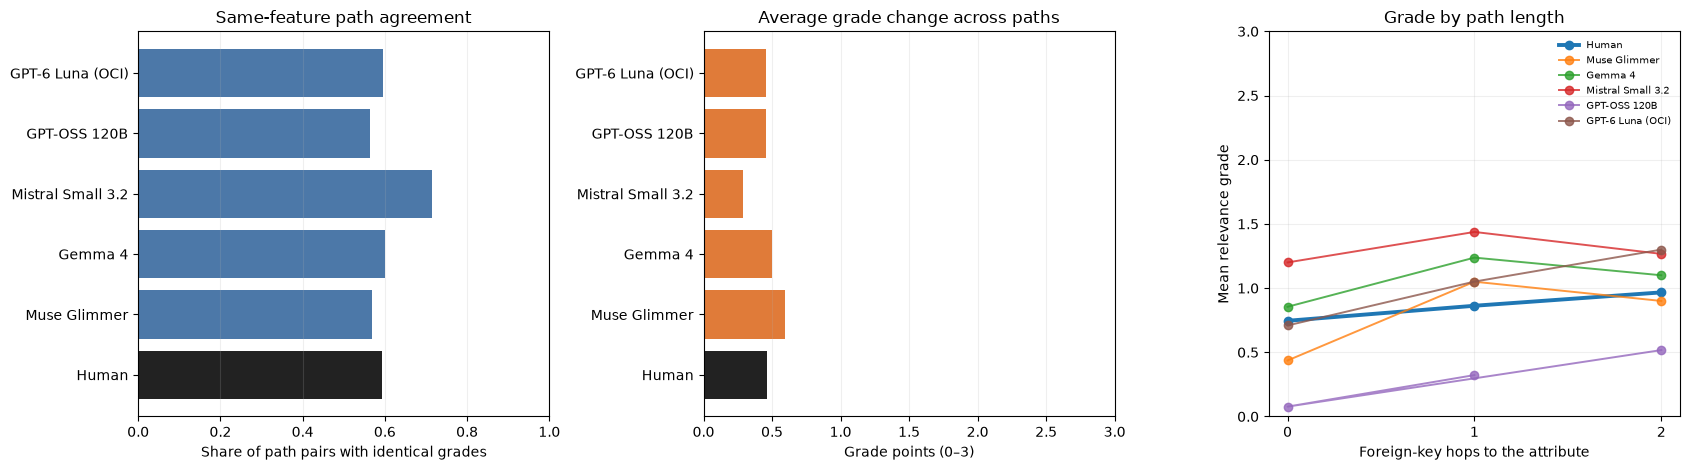

,label source,FK hops,n,mean grade,share grade ≥2
0,Human,0,55,0.75,20.0%
1,Human,1,80,0.86,22.5%
2,Human,2,30,0.97,20.0%
3,Muse Glimmer,0,55,0.44,14.5%
4,Muse Glimmer,1,80,1.05,36.2%
5,Muse Glimmer,2,30,0.90,33.3%
6,Gemma 4,0,55,0.85,34.5%
7,Gemma 4,1,80,1.24,47.5%
8,Gemma 4,2,30,1.10,46.7%
9,Mistral Small 3.2,0,55,1.20,34.5%


Dropdown(description='Feature:', layout=Layout(width='95%'), options=(('condition-001 | customer.customer_name…

Output()

In [59]:
from itertools import combinations
from IPython.display import clear_output, display, Markdown
import ipywidgets as widgets

# Start from the human-labeled catalog so every comparison uses the same
# condition–signal universe; model grades are joined where valid consensus exists.
path_matrix = human[[
    'condition_id', 'candidate_id', 'condition', 'candidate', 'human_grade'
]].copy()
path_matrix['kind'] = path_matrix['candidate'].map(lambda c: c.get('kind') if isinstance(c, dict) else None)
path_matrix = path_matrix[path_matrix['kind'].eq('attribute')].copy()
path_matrix['attribute_table'] = path_matrix['candidate'].map(lambda c: c.get('attribute_table'))
path_matrix['attribute_column'] = path_matrix['candidate'].map(lambda c: c.get('attribute_column'))
path_matrix['path_tuple'] = path_matrix['candidate'].map(lambda c: tuple(c.get('path') or ()))
path_matrix['path_hops'] = path_matrix['path_tuple'].map(lambda p: max(0, len(p) - 1))
path_matrix['path_label'] = path_matrix['path_tuple'].map(lambda p: ' → '.join(p))
path_matrix['path_diagram'] = path_matrix['candidate'].map(lambda c: c.get('path_diagram', '') if isinstance(c, dict) else '')
path_matrix['feature_key'] = (path_matrix['condition_id'] + ' | ' + path_matrix['attribute_table'].astype(str) + '.' + path_matrix['attribute_column'].astype(str))

for model_name in HUMAN_MODEL_FILES:
    model_rows = human_model_long[human_model_long['model'].eq(model_name)][['condition_id', 'candidate_id', 'model_grade']]
    model_rows = model_rows.drop_duplicates(['condition_id', 'candidate_id'])
    path_matrix = path_matrix.merge(
        model_rows.rename(columns={'model_grade': model_name}),
        on=['condition_id', 'candidate_id'], how='left', validate='one_to_one'
    )

label_sources = ['Human'] + list(HUMAN_MODEL_FILES)
grade_columns = {'Human': 'human_grade', **{name: name for name in HUMAN_MODEL_FILES}}
path_groups = []
for feature_key, group in path_matrix.groupby('feature_key', sort=True):
    group = group.drop_duplicates('candidate_id').sort_values(['path_hops', 'path_label'])
    if group['path_tuple'].nunique() >= 2:
        path_groups.append((feature_key, group))

pair_rows = []
for feature_key, group in path_groups:
    for (_, left), (_, right) in combinations(group.iterrows(), 2):
        if left['path_tuple'] == right['path_tuple']:
            continue
        for source in label_sources:
            col = grade_columns[source]
            grade_a, grade_b = left[col], right[col]
            if pd.isna(grade_a) or pd.isna(grade_b):
                continue
            grade_a, grade_b = int(grade_a), int(grade_b)
            pair_rows.append({
                'feature_key': feature_key, 'condition_id': left['condition_id'],
                'attribute': f"{left['attribute_table']}.{left['attribute_column']}",
                'source': source, 'path_a': left['path_label'], 'path_b': right['path_label'],
                'hops_a': int(left['path_hops']), 'hops_b': int(right['path_hops']),
                'grade_a': grade_a, 'grade_b': grade_b,
                'exact match': grade_a == grade_b,
                'within one grade': abs(grade_a - grade_b) <= 1,
                'absolute grade difference': abs(grade_a - grade_b),
            })

path_pairs = pd.DataFrame(pair_rows)
if path_pairs.empty:
    print('No same-feature signals with multiple judged paths were found.')
else:
    path_summary = (path_pairs.groupby('source', sort=False)
        .agg(**{
            'feature groups': ('feature_key', 'nunique'),
            'compared path pairs': ('absolute grade difference', 'size'),
            'exact grade match': ('exact match', 'mean'),
            'within-one-grade match': ('within one grade', 'mean'),
            'mean absolute grade difference': ('absolute grade difference', 'mean'),
        }).reindex(label_sources).reset_index(names='label source'))
    print(f"Compared {len(path_groups)} condition–feature groups with multiple paths; {path_pairs.groupby('source')['absolute grade difference'].size().to_dict()} valid path-pair judgments by source.")
    display(path_summary.style.format({
        'exact grade match': '{:.1%}', 'within-one-grade match': '{:.1%}',
        'mean absolute grade difference': '{:.2f}',
    }))

    # Show average grades by path length, aggregating within the same feature/condition catalog.
    path_grade_long = path_matrix.melt(
        id_vars=['feature_key', 'condition_id', 'attribute_table', 'attribute_column', 'path_label', 'path_hops'],
        value_vars=[grade_columns[source] for source in label_sources],
        var_name='grade_column', value_name='grade'
    ).dropna(subset=['grade'])
    column_to_source = {grade_columns[source]: source for source in label_sources}
    path_grade_long['label source'] = path_grade_long['grade_column'].map(column_to_source)
    hop_summary = (path_grade_long.groupby(['label source', 'path_hops'], sort=False)
        .agg(n=('grade', 'size'), mean_grade=('grade', 'mean'), grade_ge_2=('grade', lambda x: (x >= 2).mean()))
        .reset_index())
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    plot_summary = path_summary.set_index('label source').reindex(label_sources)
    axes[0].barh(label_sources, plot_summary['exact grade match'], color=['#222222' if s == 'Human' else '#4c78a8' for s in label_sources])
    axes[0].set_xlim(0, 1); axes[0].set_xlabel('Share of path pairs with identical grades')
    axes[0].set_title('Same-feature path agreement')
    axes[0].grid(axis='x', alpha=.2)
    axes[1].barh(label_sources, plot_summary['mean absolute grade difference'], color=['#222222' if s == 'Human' else '#e07b39' for s in label_sources])
    axes[1].set_xlim(0, 3); axes[1].set_xlabel('Grade points (0–3)')
    axes[1].set_title('Average grade change across paths')
    axes[1].grid(axis='x', alpha=.2)
    for source in label_sources:
        subset = hop_summary[hop_summary['label source'].eq(source)]
        axes[2].plot(subset['path_hops'], subset['mean_grade'], marker='o',
                     linewidth=2.8 if source == 'Human' else 1.4,
                     label=source, alpha=1 if source == 'Human' else .8)
    axes[2].set_xticks(sorted(path_grade_long['path_hops'].unique()))
    axes[2].set_ylim(0, 3); axes[2].set_xlabel('Foreign-key hops to the attribute')
    axes[2].set_ylabel('Mean relevance grade'); axes[2].set_title('Grade by path length')
    axes[2].grid(alpha=.2); axes[2].legend(fontsize=7, frameon=False)
    plt.tight_layout(); plt.show()

    display(hop_summary.rename(columns={'path_hops': 'FK hops', 'mean_grade': 'mean grade', 'grade_ge_2': 'share grade ≥2'}).style.format({'mean grade': '{:.2f}', 'share grade ≥2': '{:.1%}'}))

    # Browse the actual alternative paths and their grades for one feature/condition.
    feature_dropdown = widgets.Dropdown(
        options=[(key, key) for key, _ in path_groups],
        description='Feature:', layout=widgets.Layout(width='95%')
    )
    feature_output = widgets.Output()
    def show_path_feature(change=None):
        with feature_output:
            clear_output(wait=True)
            selected = path_matrix[path_matrix['feature_key'].eq(feature_dropdown.value)].copy()
            selected = selected.drop_duplicates('candidate_id').sort_values(['path_hops', 'path_label'])
            view = pd.DataFrame({
                'path': selected['path_label'], 'FK hops': selected['path_hops'],
                'signal ID': selected['candidate_id'],
                **{source: selected[grade_columns[source]].map(lambda x: '—' if pd.isna(x) else int(x)) for source in label_sources},
            })
            display(view)
            for _, row in selected.iterrows():
                diagram = row['path_diagram']
                if isinstance(diagram, str) and diagram.strip():
                    display(Markdown(f"**{row['attribute_table']}.{row['attribute_column']} via {row['path_label']}**\n\n```text\n{diagram}\n```"))
    feature_dropdown.observe(show_path_feature, names='value')
    display(feature_dropdown, feature_output)
    show_path_feature()